In [1]:
# Import section
from config import hparams
from dataset import CombinedDataset
from model import VariationalAutoencoder

import numpy as np

import torch
from torch.utils.data import DataLoader, random_split
import torch.nn as nn

from music21 import converter, note, stream, meter

#from fastdtw import fastdtw
#from dtw import dtw
from dtaidistance import dtw

from scipy.signal import butter, filtfilt

import matplotlib.pyplot as plt

cpu


In [2]:
seed = 123
np.random.seed(seed)
_ = torch.manual_seed(seed)
_ = torch.cuda.manual_seed(seed)

In [3]:
# Work on GPU if it is available in the machine, otherwise run on CPU
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

Definition of the Pytorch Dataset and DataLoader

In [4]:
# Definition of the dataset folders
irish_root = 'C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irishtunes_dataset'
synthetic_root = 'C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/synthetics_dataset'

# Create one dataset for all data
combined_dataset = CombinedDataset(irish_root, synthetic_root)

# Determine split sizes
total_size = len(combined_dataset)
train_size = int(0.6 * total_size)
val_size = int(0.3 * total_size)
test_size = total_size - train_size - val_size

# Split the dataset
train_dataset, val_dataset, test_dataset = random_split(
    combined_dataset, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

# Dataloaders initialization
train_dataloader = torch.utils.data.DataLoader(
    dataset=train_dataset,
    batch_size=hparams['batch_size'],
    shuffle=True,
    drop_last=False,
)

val_dataloader = torch.utils.data.DataLoader(
    dataset=val_dataset,
    batch_size=hparams['batch_size'],
    shuffle=False,
    drop_last=False,
)

test_dataloader = torch.utils.data.DataLoader(
    dataset=test_dataset,
    batch_size=1,
    shuffle=True,
    drop_last=False,
)

In [5]:
# Function for extracting ground truth vectors
def compute_true_vectors(bar2_pitches):
    """
    Obtain Tmidi true and Trp true from the ground truth pitch vector of the 2nd bar

    Args:
        bar2_pitches: [B, 48] of MIDI pitches (0 means rest)

    Returns:
        tmidi_true: [B, 24] tokens (0-127 = notes, 128 = hold, 129 = rest)
        trp_true: [B, 24] quantized relative pitch curve'
    """

    # Define constants from hparams
    batch = bar2_pitches.size(0)
    seq_len_dataset = hparams['seq_len_dataset']
    seq_len = hparams['seq_len']

    # Define grid beat ticks
    beat_ticks = [0, 1/4, 1/3, 1/2, 2/3, 3/4] # 6 uneven ticks per beat -> 24 ticks per measure

    # Define quantization bins
    bins = np.array([-9, -5, -1, 0, 1, 5, 9], dtype=np.float32)

    # Define empty vectors
    tmidi_true = torch.zeros(batch, seq_len, dtype=torch.float32)
    trp_true = torch.zeros(batch, seq_len, dtype=torch.float32)
    vchroma_true = torch.zeros(batch, 12, dtype=torch.float32)

    # Create new grid
    # - In seq_len_dataset = 48, the grid is even, so 12 steps per beat (48/4)
    # - Map the 6 uneven ticks into 12 uniform steps
    tick_indices = np.zeros_like(beat_ticks) # = [0, 3, 4, 6, 8, 9]
    for t in range(len(beat_ticks)):
        tick_indices[t] = round(beat_ticks[t]*12)

    # - Create grid
    grid = [] # = [0, 3, 4, 6, 8, 9, 12, 15, 16, 18, 20, 21, 24, 27, 28, 30, 32, 33, 36, 39, 40, 42, 44, 45]
    for beat in range(4):
        base = beat * 12
        for tick in tick_indices:
            grid += [int(base + tick)]

    for b in range(batch):
        pitches = bar2_pitches[b] # has seq_len_dataset

        # Compute vchroma_true
        # Get pitch classes
        pitch_classes = np.unique(pitches % 12)
        # Set active classes to 1
        vchroma_true[b, pitch_classes] = 1.0

        # Map bar2_pitches to uneven 24-positions grid
        pitches = pitches[grid] # has seq_len

        # Compute Tmidi_true
        # Go through the pitch vector of each batch
        for t in range(seq_len):
            if pitches[t] == 0:
                tmidi_true[b,t] = 129 # rest condition
            elif t>0 and pitches[t] == pitches[t-1] and pitches[t] != 0:
                tmidi_true[b,t] = 128 # hold condition
            else:
                tmidi_true[b,t] = pitches[t] # MIDI pitch number for onset position
        
        # Compute Trp_true
        # Get the onsets vector
        onsets = np.where((tmidi_true[b] >= 0) & (tmidi_true[b] <= 127))[0]

        if len(onsets) >= 2:
            for pos in range(len(onsets) - 1):
                # For every pair of consecutive onsets in positions i and j = i + n where n > 0, 
                # Calculate the MIDI interval Δ = Tmidi[j] - Tmidi[i]
                i = onsets[pos].item()
                j = onsets[pos + 1].item()
                delta = tmidi_true[b, j] - tmidi_true[b, i]
                n = j - i

                # Then perform a linear interpolation between i + 1 and j (k points), resulting in Trp[k]
                for k in range(i+1, j+1):
                    trp_true[b, k] = delta * ((k-i)/n)
        
        # Quantize Trp_true
        trp_quantizated = torch.zeros(batch, seq_len, dtype=torch.float32)
        bins_tensor = torch.tensor(bins) # convert to tensor so it can be comptatible with trp_true
        for k in range(seq_len):
            diff = np.abs(bins_tensor - trp_true[b, k])
            nearest_bin_idx = np.argmin(diff)
            trp_quantizated[b, k] = nearest_bin_idx
    
    return tmidi_true, trp_quantizated, vchroma_true

In [6]:
# Define loss function
def loss_function(trp_pred, trp_true, tmidi_pred, tmidi_true,
                  lambda_trp, lambda_tmidi,
                  vchroma_pred, vchroma_true,
                  lambda_chroma,
                  zrp_mu, zrp_logvar, zc_mu, zc_logvar, variational_beta):
    
    # Flatten batch + time before computing cross-entropies
    B, T, Vtrp  = trp_pred.shape
    _, _, Vmidi = tmidi_pred.shape

    trp_pred_flat   = trp_pred.reshape(B*T, Vtrp)
    trp_true_flat   = trp_true.reshape(B*T)
    tmidi_pred_flat = tmidi_pred.reshape(B*T, Vmidi)
    tmidi_true_flat = tmidi_true.reshape(B*T)

    # Compute cross-entropy losses
    ce = nn.CrossEntropyLoss()
    ce_loss_trp   = ce(trp_pred_flat, trp_true_flat) * lambda_trp
    ce_loss_tmidi = ce(tmidi_pred_flat, tmidi_true_flat) * lambda_tmidi

    # Compute binary cross-entropy loss
    bce = nn.BCEWithLogitsLoss()
    bce_loss_chroma = lambda_chroma * bce(vchroma_pred, vchroma_true.float())

    # Compute KL divergence loss
    kl_loss_zrp = -0.5 * torch.mean(1 + zrp_logvar - zrp_mu.pow(2) - zrp_logvar.exp())
    kl_loss_zc = -0.5 * torch.mean(1 + zc_logvar - zc_mu.pow(2) - zc_logvar.exp())
    kl_total = variational_beta * (kl_loss_zrp + kl_loss_zc)

    # Weighted sum
    loss_total = ce_loss_trp + ce_loss_tmidi + bce_loss_chroma + kl_total

    return loss_total, ce_loss_trp, ce_loss_tmidi, bce_loss_chroma, kl_total

Load trained model

In [7]:
checkpoint_path = 'C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/checkpoints/best_model.pth'
checkpoint = torch.load(checkpoint_path, map_location = torch.device('cpu'))

model = VariationalAutoencoder(hparams['channels'], hparams['latent_dim'], hparams['vocab_size'], hparams['seq_len'], hparams['frp_len'], hparams['n_layers_encoder'], hparams['embedding_dim'], hparams['n_layers_gru'], hparams['hidden_dim_gru'], hparams['vocab_size_Trp'], hparams['chroma_dim'])
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
print('Model loaded')

Model loaded


Evaluate test samples

In [8]:
def extract_true_rhythm(true_tokens, pred_tokens):
    # Extract true rhythm from true tokens
    true_rhythm = []
    for tok in true_tokens:
        if tok == 128:  # hold
            true_rhythm.append(1)
        elif tok == 129:  # rest
            true_rhythm.append(2)
        else: # onset
            true_rhythm.append(0)
    
    # Apply rhythm enforcement to predicted tokens
    tokens_r = []
    last_pitch = None

    for i, rhythm in enumerate(true_rhythm):
        if rhythm == 0:  # onset
            if pred_tokens[i] < 128: # pred_tokens has valid onset in i
                tokens_r.append(pred_tokens[i])
                last_pitch = pred_tokens[i]
            elif last_pitch is not None: # pred_tokens has hold or rest, use last valid pitch
                tokens_r.append(last_pitch)
            else: # no valid pitch yet, use rest
                tokens_r.append(129)
        elif rhythm == 1:  # hold
            tokens_r.append(128)
        elif rhythm == 2:  # rest
            tokens_r.append(129)

    return tokens_r

In [9]:
def extract_pitch_contour(tokens):
    pitches = []
    onsets = []
    
    # Extract contours
    last_pitch = None
    for i, tok in enumerate(tokens):
        if tok < 128:  # onset
            pitches.append(tok)
            last_pitch = tok
            onsets.append(i)
    
    onsets = np.array(onsets, dtype=np.float32)
    pitches = np.array(pitches, dtype=np.int16)

    # Compute the relative pitch function
    frp_len = hparams['frp_len']
    filter_cutoff = 1/50
    filter_order = 5

    # Piecewise-linear interpolation
    x = np.linspace(onsets.min(), onsets.max(), frp_len)
    y = np.interp(x, onsets, pitches)

    # Low-pass Butterworth filtering
    # to smooth the linear interpolation
    b, a = butter(filter_order, filter_cutoff, btype='low')
    y_smooth = filtfilt(b, a, y)

    # Normalization
    # Find midpoint in the curve range
    pitch_range = y_smooth.max() - y_smooth.min()
    middle_val = y_smooth.min() + pitch_range/2

    # Substract midpoint and divide by 12
    # 12 because 12 semitones = 1 octave
    frp = (y_smooth - middle_val) / 12.0

    return frp.astype(np.float32)

In [10]:
# Test
tokens_pred = [81, 128, 128,  78, 128, 128,  76, 128, 128,  73, 128, 128,  74, 128,
         128,  71, 128, 128,  69, 128, 128,  66, 128, 128]
tokens_true = [81, 128, 128,  76, 128, 78,  128, 128, 128,  73, 128, 128,  74, 128,
         128,  71, 128, 128,  69, 128, 128,  66, 128, 128]
print(tokens_pred)
print(tokens_true)

# With rhythm enforcement
pred_tokens_r = extract_true_rhythm(tokens_true, tokens_pred)
print(pred_tokens_r)

# Extract contour
contour_pred = extract_pitch_contour(tokens_pred)
contour_true = extract_pitch_contour(tokens_true)
contour_pred_r = extract_pitch_contour(pred_tokens_r)
print(contour_pred.size)
print(contour_true.size)
print(contour_pred_r.size)

# Compute DTW
distance = dtw.distance(contour_pred, contour_pred)
distance_r = dtw.distance(contour_pred_r, contour_true)
print(distance)
print(distance_r)

[81, 128, 128, 78, 128, 128, 76, 128, 128, 73, 128, 128, 74, 128, 128, 71, 128, 128, 69, 128, 128, 66, 128, 128]
[81, 128, 128, 76, 128, 78, 128, 128, 128, 73, 128, 128, 74, 128, 128, 71, 128, 128, 69, 128, 128, 66, 128, 128]
[81, 128, 128, 78, 128, 78, 128, 128, 128, 73, 128, 128, 74, 128, 128, 71, 128, 128, 69, 128, 128, 66, 128, 128]
512
512
512
0.0
0.25286734854813003


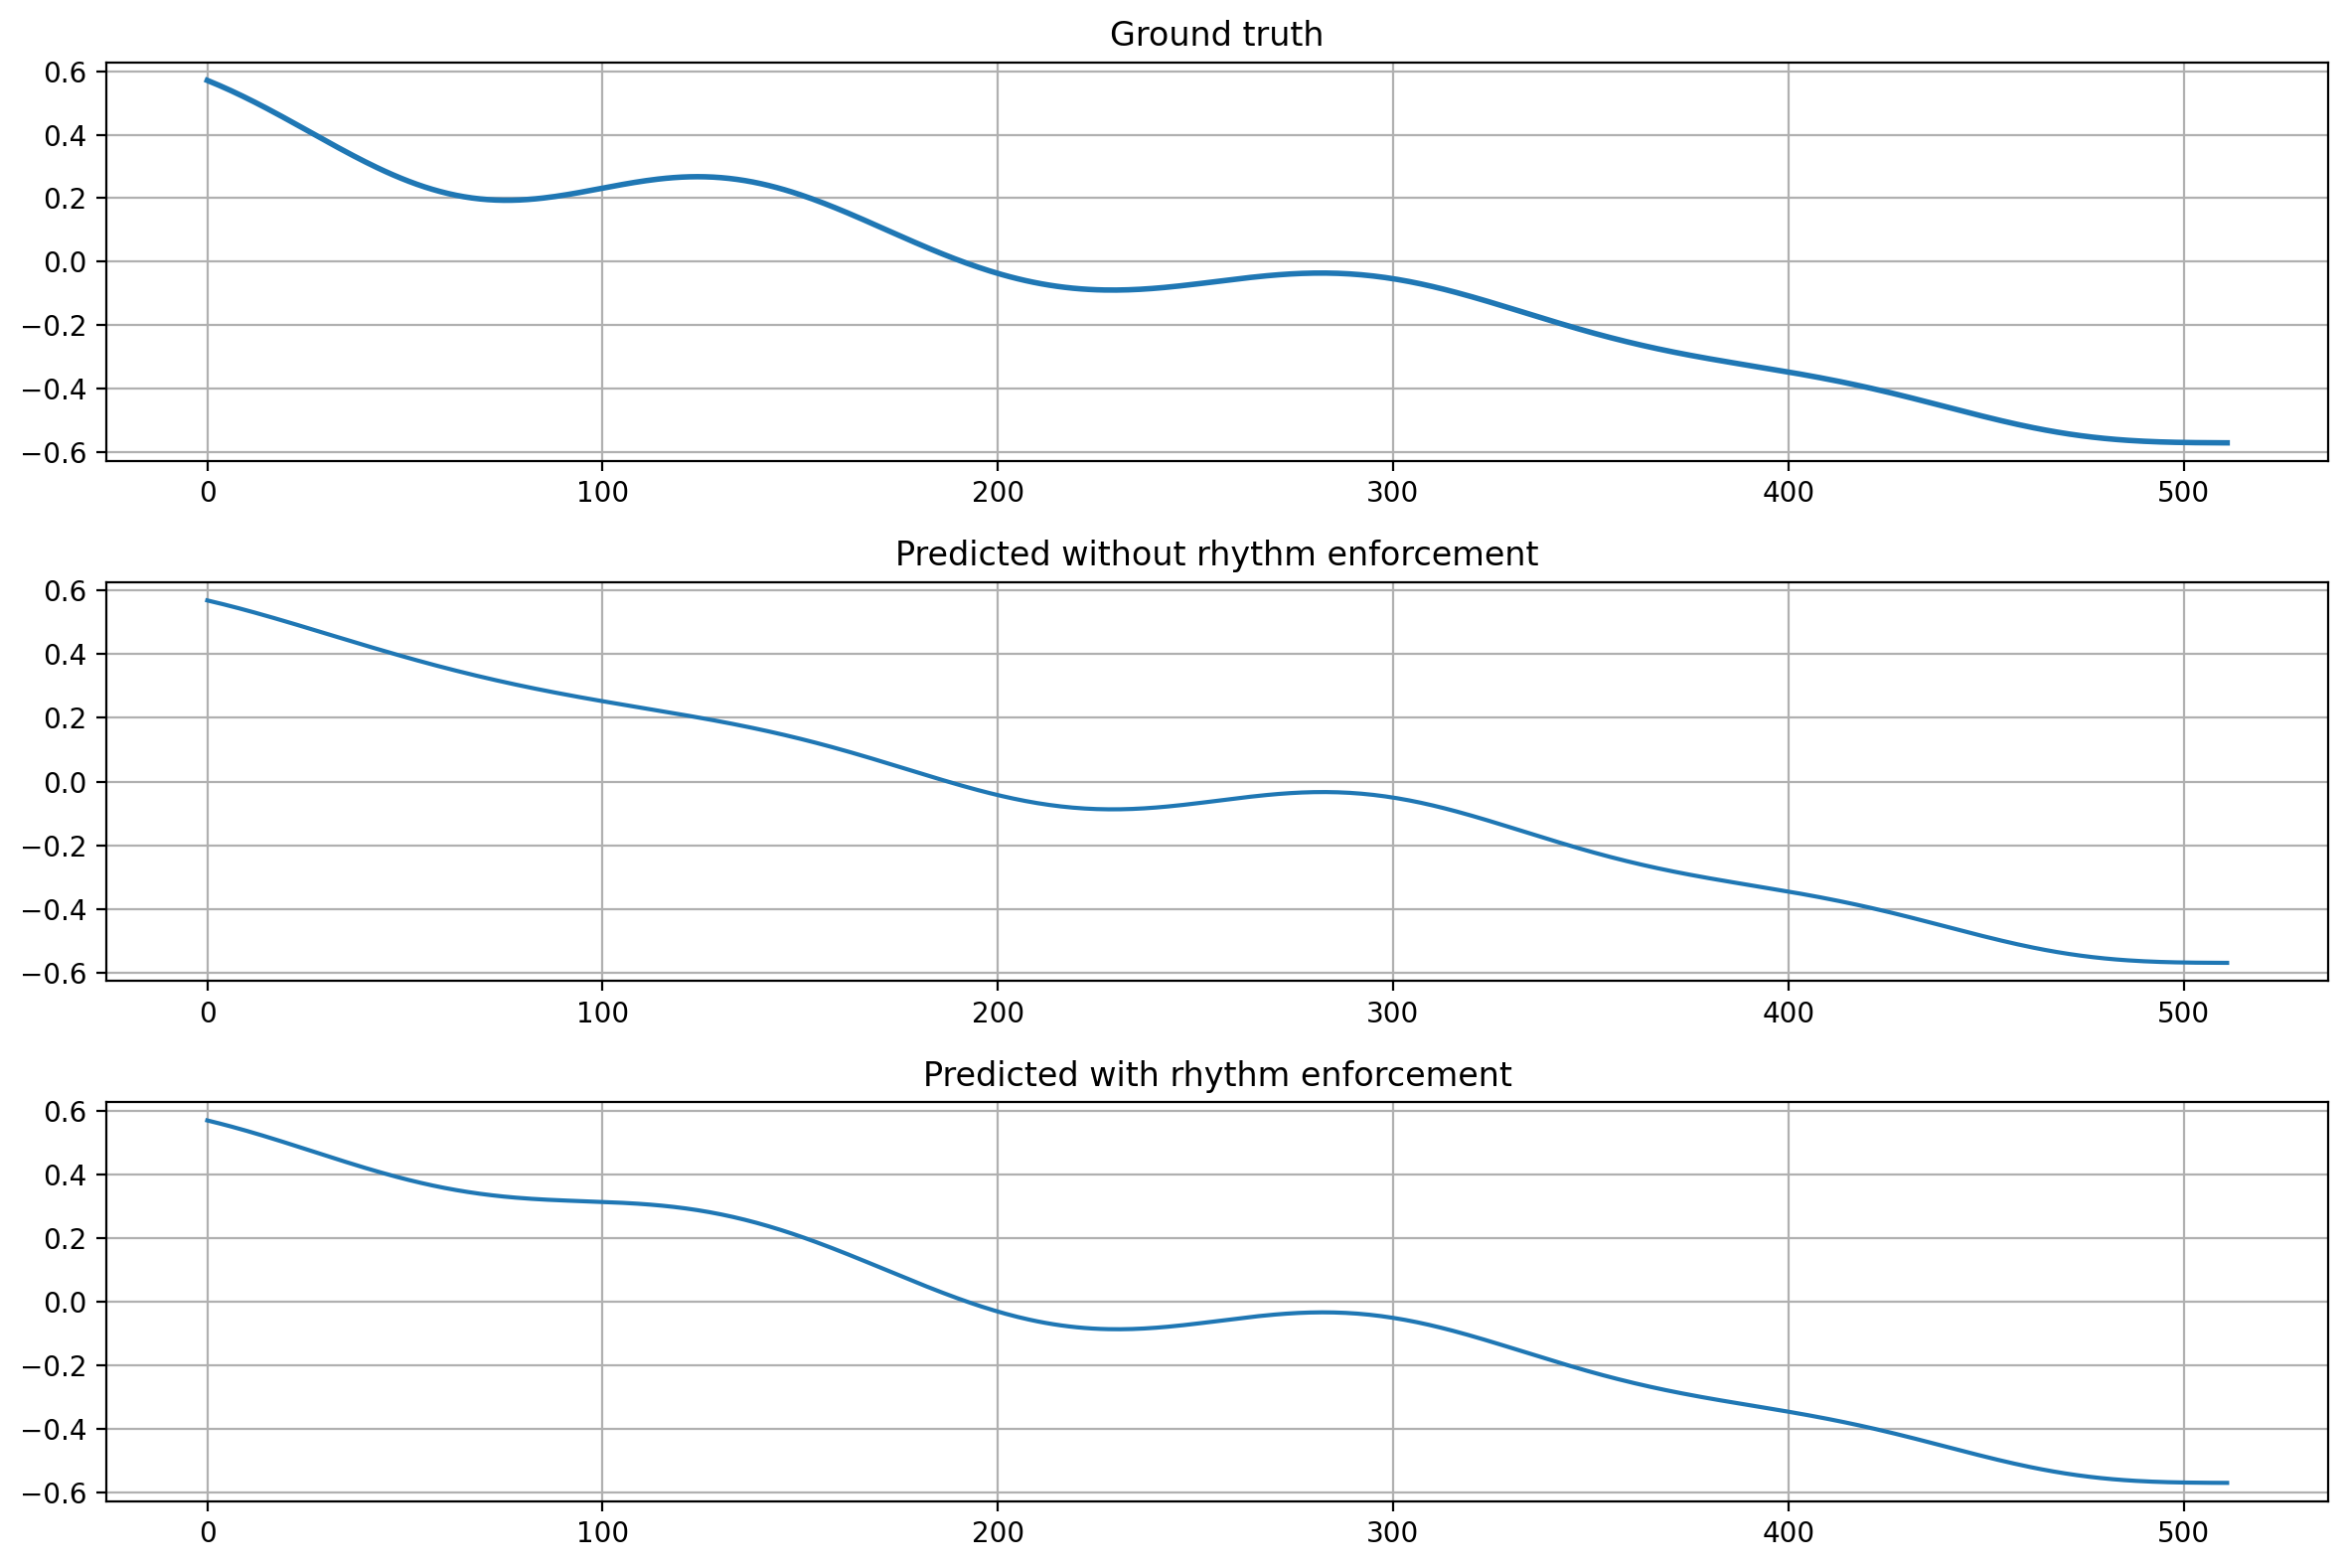

In [11]:
plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(contour_true, linewidth=2)
plt.title("Ground truth")
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(contour_pred)
plt.title("Predicted without rhythm enforcement")
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(contour_pred_r)
plt.title("Predicted with rhythm enforcement")
plt.grid(True)

plt.tight_layout()
plt.show()


In [12]:
def extract_rhythm_contour(tokens):
    # Compute durations of all notes
    durations = np.zeros(len(tokens))
    element = 0

    while element < len(tokens):
        if tokens[element] < 128: # Note onset
            dur = 1
            next_element = element + 1
            while next_element < len(tokens) and tokens[next_element] == 128:  # Hold
                dur += 1
                next_element += 1
            durations[element] = dur
            element = next_element
        else: # Rest or hold
            element += 1
    #print(durations)

    # Convert durations into density
    density = np.zeros(len(tokens))

    last_density = 0.0
    for i in range(len(tokens)):
        if durations[i] > 0:
            relative_duration = durations[i] / len(tokens)
            last_density = np.log2(1/relative_duration)
        density[i] = last_density
    #print(density)
    
    # 3-level quantization
    quantized_density = np.zeros(len(tokens))
    quantized_density[(density > 0) & (density <= 1.25)] = 0
    quantized_density[(density > 1.25) & (density <= 3.29)] = 1
    quantized_density[density > 3.29] = 2
    #print(quantized_density)

    # Subtract the minimum value
    frr = quantized_density - np.min(quantized_density)

    return frr

In [13]:
# Test
tokens_pred = [81, 128, 71,  78, 128, 128,  76, 128, 128,  73, 128, 128,  74, 128,
         128,  71, 128, 128,  69, 128, 128,  66, 128, 128]
tokens_true = [81, 128, 128,  76, 128, 128,  78, 128, 128,  73, 128, 128,  74, 128,
         128,  71, 128, 128,  69, 128, 128,  66, 128, 128]
print(tokens_pred)
print(tokens_true)

contour_pred = extract_rhythm_contour(tokens_pred)
contour_true = extract_rhythm_contour(tokens_true)
print(contour_pred)
print(contour_true)

# Compute DTW
distance = dtw.distance(contour_pred, contour_true)
print(distance)

[81, 128, 71, 78, 128, 128, 76, 128, 128, 73, 128, 128, 74, 128, 128, 71, 128, 128, 69, 128, 128, 66, 128, 128]
[81, 128, 128, 76, 128, 128, 78, 128, 128, 73, 128, 128, 74, 128, 128, 71, 128, 128, 69, 128, 128, 66, 128, 128]
[1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
1.7320508075688772


In [14]:
def extract_pitch_classes(tokens):
    pitch_classes = []
    for tok in tokens:
        if tok < 128: # ignore holds and rests
            pitch_classes.append(tok % 12)
    return pitch_classes

In [15]:
def estimate_key(pitch_classes):
    # Krumhansl key profiles
    major_profile = np.array([6.35, 2.23, 3.48, 2.33, 4.38, 4.09,
                              2.52, 5.19, 2.39, 3.66, 2.29, 2.88])
    minor_profile = np.array([6.33, 2.68, 3.52, 5.38, 2.60, 3.53,
                              2.54, 4.75, 3.98, 2.69, 3.34, 3.17])
    
    # Count occurrences of each pitch class
    pitch_class_counts = np.zeros(12)
    for pc in pitch_classes:
        pitch_class_counts[pc] += 1

    if pitch_class_counts.sum() == 0:
        return None, None, set()  # No pitch classes found
    
    pitch_class_counts /= pitch_class_counts.sum()  # Normalize counts
    
    # Compute correlation with each key profile
    max_correlation = -np.inf
    best_tonic = None
    best_mode = None
    for tonic in range(12):
        # Rotate profiles to match tonic
        rotated_major = np.roll(major_profile, tonic)
        rotated_minor = np.roll(minor_profile, tonic)
        
        # Compute correlation
        corr_major = np.corrcoef(pitch_class_counts, rotated_major)[0, 1]
        corr_minor = np.corrcoef(pitch_class_counts, rotated_minor)[0, 1]
        
        # Update best key if needed
        if corr_major > max_correlation:
            max_correlation = corr_major
            best_tonic = tonic
            best_mode = 'major'
        if corr_minor > max_correlation:
            max_correlation = corr_minor
            best_tonic = tonic
            best_mode = 'minor'
    
    # Determine the set of pitch classes in the estimated key
    if best_mode == 'major':
        scale = {0, 2, 4, 5, 7, 9, 11}
    else:
        scale = {0, 2, 3, 5, 7, 8, 10}

    key_pcs = set()
    for interval in scale:
        key_pcs.add((best_tonic + interval) % 12)

    return best_tonic, best_mode, key_pcs

In [16]:
def context_matching(tokens_pred, tokens_context):
    # Extract the pitch classes from the notes
    pitch_classes_pred = extract_pitch_classes(tokens_pred)
    pitch_classes_context = extract_pitch_classes(tokens_context)
    
    # Estimate key using Krumhansl algorithm
    key_tonic, key_mode, key_pcs = estimate_key(pitch_classes_context)
    
    NOTE_NAMES = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']
    best_tonic_name = NOTE_NAMES[key_tonic] if key_tonic is not None else None
    #print(f'Estimated key: {best_tonic_name} {key_mode}')

    if len(pitch_classes_pred) == 0 or len(key_pcs) == 0:
        return 0.0

    # Percentage of notes belonging to the estimated key
    matches = 0
    for pc in pitch_classes_pred:
        if pc in key_pcs:
            matches += 1
    percentage_in_key = int(matches / len(pitch_classes_pred) * 100)
    return percentage_in_key

In [23]:
# Test
tokens_pred = [82, 128, 83, 84, 128, 128, 80, 128, 128, 75, 128, 128, 81, 128,
               128, 72, 128, 128, 70, 128, 128, 67, 128, 128]
tokens_context = [81, 128, 128, 76, 128, 128, 78, 128, 128, 73, 128, 128, 74,
                  128, 128, 71, 128, 128, 69, 128, 128, 66, 128, 128]

tokens_pred = [74, 128, 128, 76, 128, 128, 72, 128, 128, 69, 128, 128, 71, 128, 128, 67, 128, 128, 128, 128, 128, 128, 128, 128]
tokens_context = [66, 128, 128, 128, 128, 128, 62, 128, 128, 128, 128, 128, 66, 128, 128, 128, 128, 128, 67, 128, 128, 128, 128, 128, 69, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 78, 128, 128, 128, 128, 128, 76, 128, 128, 128, 128, 128, 128, 74, 128, 128, 128, 128, 128, 76, 128, 128, 128, 128, 128, 72, 128, 128, 128, 128, 128, 69, 128, 128, 128, 128, 128, 71, 128, 128, 128, 128, 67, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128, 128]

all_tokens = np.concatenate([tokens_pred, tokens_context])
print(all_tokens)

percentage_in_key = context_matching(tokens_pred, tokens_context)
print(percentage_in_key)

[ 74 128 128  76 128 128  72 128 128  69 128 128  71 128 128  67 128 128
 128 128 128 128 128 128  66 128 128 128 128 128  62 128 128 128 128 128
  66 128 128 128 128 128  67 128 128 128 128 128  69 128 128 128 128 128
 128 128 128 128 128  78 128 128 128 128 128  76 128 128 128 128 128 128
  74 128 128 128 128 128  76 128 128 128 128 128  72 128 128 128 128 128
  69 128 128 128 128 128  71 128 128 128 128  67 128 128 128 128 128 128
 128 128 128 128 128 128 128 128 128 128 128 128]
83


In [18]:
def tmidi_to_score(tmidi_tokens, seq_len):
    score = stream.Stream()
    score.append(meter.TimeSignature('4/4'))
    tick_duration = 4.0 / seq_len

    # Definition of previous element
    prev_element = None

    # Go through every element of tmidi
    for element in tmidi_tokens:
        if 1 <= element <= 127:
            # MIDI pitch onset
            n = note.Note(int(element))
            n.quarterLength = tick_duration
            score.append(n)
            prev_element = n

        elif element == 128:
            # Hold token
            if prev_element is not None:
                prev_element.quarterLength += tick_duration
            # else ignore invalid continuation

        elif element == 129:
            # Rest token
            r = note.Rest()
            r.quarterLength = tick_duration
            score.append(r)
            prev_element = r

        else:
            # silently skip invalid tokens, including tok=0
            pass

    return score

In [19]:
# Define the matching lists
pitch_match_list = []
rhythm_match_list = []
context_match_list = []

In [20]:
num_eval = 1 # change to 1000

loader_iter = iter(test_dataloader)

model.eval()

with torch.no_grad():
    for i in range(num_eval):
        sample_1 = next(loader_iter) # bar1_pitches, bar2_pitches, frp, midi_path
        sample_2 = next(loader_iter) # bar1_pitches, bar2_pitches, frp, midi_path

        # Extract useful information
        bar11 = sample_1[0] # bar1_pitches
        x_context = bar11.int().unsqueeze(1).to(device)
        bar12 = sample_1[1] # bar2_pitches

        bar22 = sample_2[2] # frp
        x_curve = sample_2[2].float().unsqueeze(1).to(device)

        tmidi_true, _, _ = compute_true_vectors(sample_1[1])
        tmidi_true = tmidi_true.long().to(device)

        # Generate new bar
        bar3 = model(x_curve, x_context) # tmidi_pred, trp_pred, vchroma_pred, zrp_mu, zrp_logvar, zc_mu, zc_logvar
        tmidi_pred = bar3[0]

        # Get tokens from bars
        tmidi_true_tokens = tmidi_true[0]
        tmidi_pred_tokens = tmidi_pred[0].argmax(dim=-1).cpu().numpy()
        context_tokens = np.concatenate((bar11[0].int(), bar12[0].int())) # all bars from context sample
        #print(context_tokens)

        # Pitch contour matching
        # Extract contour
        tmidi_pred_pitch = extract_pitch_contour(tmidi_pred_tokens)
        #print(tmidi_pred_pitch)
        tmidi_true_pitch = extract_pitch_contour(tmidi_true_tokens)
        #print(tmidi_true_pitch)

        # Compute DTW
        pitch_cost = dtw.distance(tmidi_pred_pitch, tmidi_true_pitch)
        #print(pitch_cost)
        pitch_match_list.append(pitch_cost)

        # Rhythm contour matching
        # Extract contour
        tmidi_pred_rhythm = extract_rhythm_contour(tmidi_pred_tokens)
        #print(tmidi_pred_rhythm)
        tmidi_true_rhythm = extract_rhythm_contour(tmidi_true_tokens)
        #print(tmidi_true_rhythm)

        # Compute DTW
        rhythm_cost = dtw.distance(tmidi_pred_rhythm, tmidi_true_rhythm)
        #print(rhythm_cost)
        rhythm_match_list.append(rhythm_cost)

        # Context matching
        percentage_in_key = context_matching(tmidi_pred_tokens, context_tokens)
        #print(percentage_in_key)
        context_match_list.append(percentage_in_key)

        # Save the results
        #print("First sample")
        #sample_1_score = converter.parse(str(sample_1[3][0])).measure(1)
        #sample_1_score.write('midi', fp=f"Midi_Eval/sample_1_{i}.mid")
        #sample_1_score.show()

        #print("Second sample")
        #sample_2_score = converter.parse(str(sample_2[3][0])).measure(2)
        #sample_2_score.write('midi', fp=f"Midi_Eval/sample_2_{i}.mid")
        #sample_2_score.show()

        #print("Generated melody")
        #generated_score = tmidi_to_score(tmidi_pred_tokens, hparams['seq_len'])
        #generated_score.write('midi', fp=f"Midi_Eval/generated_score_{i}.mid")
        #generated_score.show()                                                                                  


C:\Users\cristinj\AppData\Local\Temp\ipykernel_4600\3223435703.py:87: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  diff = np.abs(bins_tensor - trp_true[b, k])


ValueError: zero-size array to reduction operation minimum which has no identity

In [ ]:
print(pitch_match_list)
print(rhythm_match_list)
print(context_match_list)

[inf]
[0.0]
[0.0]
